In [2]:
!pip install transformers torch

In [3]:
from text_analyzer import analyze_text_sentiment
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [8]:
text = "The service was excellent"

result = analyze_text_sentiment(text)

print("Input:", text)
print("\nFinal Prediction:")
print("Label:", result.label)
print("Confidence:", result.score)

print("\nAll Scores:")
print(result.scores)

print("\nModel Comparison:")
print(result.model_comparison)

Input: The service was excellent

Final Prediction:
Label: positive
Confidence: 0.9654

All Scores:
{'positive': 1.0, 'negative': 0.0, 'neutral': 0.0}

Model Comparison:
{'roberta': 0.9654, 'distilbert': 0.9812, 'bert': 0.6953}


In [10]:
import pandas as pd
from text_analyzer import analyze_text_sentiment

text = "The service was excellent"
result = analyze_text_sentiment(text)

# Convert to table
df = pd.DataFrame(list(result.model_comparison.items()), columns=["Model", "Score"])

df

,Model,Score
0,roberta,0.9654
1,distilbert,0.9812
2,bert,0.6953


In [12]:
texts = [
    "The service was excellent",
    "The flight was terrible",
    "It was okay",
    "Amazing experience",
    "Very bad service"
]

results = []

for t in texts:
    r = analyze_text_sentiment(t)
    
    results.append({
        "text": t,
        "prediction": r.label,
        "roberta": r.model_comparison.get("roberta", 0),
        "distilbert": r.model_comparison.get("distilbert", 0),
        "bert": r.model_comparison.get("bert", 0)
    })

import pandas as pd
df = pd.DataFrame(results)

df

,text,prediction,roberta,distilbert,bert
0,The service was excellent,positive,0.9654,0.9812,0.6953
1,The flight was terrible,negative,0.9234,0.9605,0.7180
2,It was okay,positive,0.6654,0.3893,0.0000
3,Amazing experience,positive,0.9639,0.9332,0.8169
4,Very bad service,negative,0.8446,0.8600,0.8763


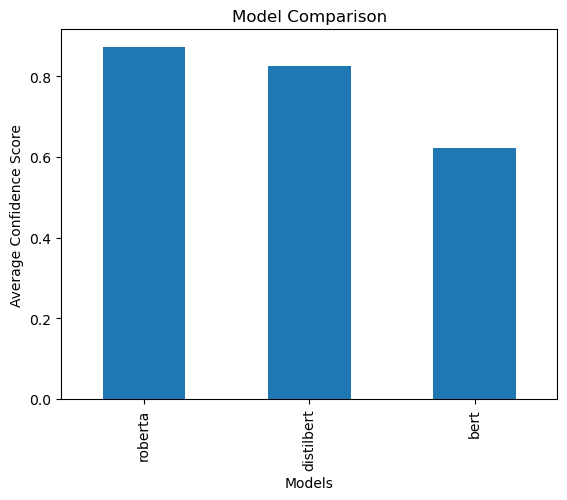

In [13]:
df[["roberta", "distilbert", "bert"]].mean().plot(kind='bar')

import matplotlib.pyplot as plt
plt.xlabel("Models")
plt.ylabel("Average Confidence Score")
plt.title("Model Comparison")
plt.show()

In [19]:
true_labels = ["positive", "negative", "neutral", "positive", "negative"]

predictions = df["prediction"].tolist()

acc = accuracy_score(true_labels, predictions)

print("Accuracy:", acc)

Accuracy: 0.8


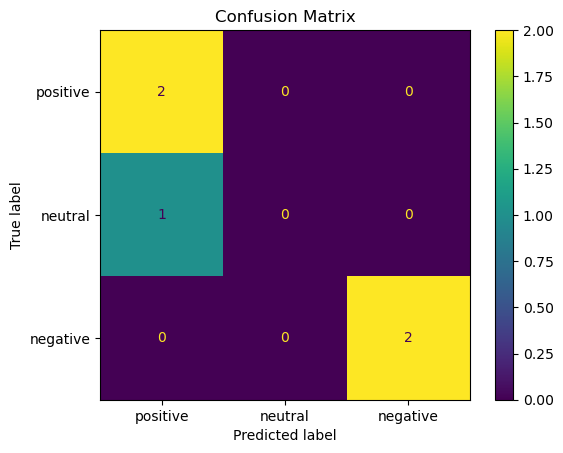

In [21]:
cm = confusion_matrix(true_labels, predictions, labels=["positive", "neutral", "negative"])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["positive", "neutral", "negative"])
disp.plot()

plt.title("Confusion Matrix")
plt.show()

In [23]:
from sklearn.metrics import classification_report
import pandas as pd

true_labels = ["positive", "negative", "neutral", "positive", "negative"]
predictions = df["prediction"].tolist()

report = classification_report(true_labels, predictions, output_dict=True)

report_df = pd.DataFrame(report).transpose()
report_df

C:\Users\muska\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\muska\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\muska\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,precision,recall,f1-score,support
negative,1.000000,1.000000,1.00,2.0
neutral,0.000000,0.000000,0.00,1.0
positive,0.666667,1.000000,0.80,2.0
accuracy,0.800000,0.800000,0.80,0.8
macro avg,0.555556,0.666667,0.60,5.0
weighted avg,0.666667,0.800000,0.72,5.0


In [29]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    true_labels,
    predictions,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df

,precision,recall,f1-score,support
negative,1.000000,1.000000,1.00,2.0
neutral,0.000000,0.000000,0.00,1.0
positive,0.666667,1.000000,0.80,2.0
accuracy,0.800000,0.800000,0.80,0.8
macro avg,0.555556,0.666667,0.60,5.0
weighted avg,0.666667,0.800000,0.72,5.0


In [31]:
metrics = report_df.loc[["positive", "negative", "neutral"], ["precision", "recall", "f1-score"]]

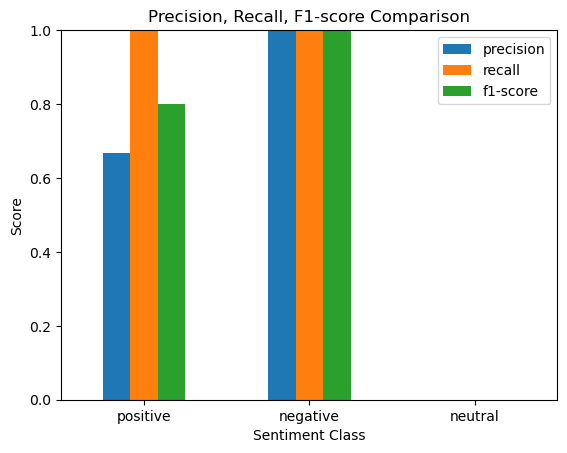

In [33]:
import matplotlib.pyplot as plt

metrics.plot(kind='bar')

plt.title("Precision, Recall, F1-score Comparison")
plt.xlabel("Sentiment Class")
plt.ylabel("Score")

plt.xticks(rotation=0)
plt.ylim(0, 1)   # IMPORTANT

plt.show()